In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/books_raw.csv")
df.shape


(175, 13)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   book_id         175 non-null    int64  
 1   title           175 non-null    str    
 2   category        175 non-null    str    
 3   product_url     175 non-null    str    
 4   image_url       175 non-null    str    
 5   image_path      175 non-null    str    
 6   description     175 non-null    str    
 7   price           175 non-null    float64
 8   rating          175 non-null    int64  
 9   upc             175 non-null    str    
 10  price_incl_tax  175 non-null    float64
 11  availability    175 non-null    int64  
 12  num_reviews     175 non-null    int64  
dtypes: float64(2), int64(4), str(7)
memory usage: 17.9 KB


In [3]:
df.nunique()

book_id           175
title             175
category            2
product_url       175
image_url         175
image_path        175
description       175
price             170
rating              5
upc               175
price_incl_tax    170
availability       19
num_reviews         1
dtype: int64

In [4]:
df.head()

,book_id,title,category,product_url,image_url,image_path,description,price,rating,upc,price_incl_tax,availability,num_reviews
0,998,Soumission,Fiction,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/ee/cf/e...,data/raw/images/6957f44c3847a760.jpg,"Dans une France assez proche de la nôtre, un h...",50.10,1,6957f44c3847a760,50.10,20,0
1,958,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/05/87/0...,data/raw/images/b12b89017878a60d.jpg,Paris is burning--and only Private's Jack Morg...,47.61,5,b12b89017878a60d,47.61,17,0
2,954,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/87/a2/8...,data/raw/images/8d455c7539795d2a.jpg,"The Freeman family--Charles, Laurel, and their...",50.27,5,8d455c7539795d2a,50.27,16,0
3,946,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/8c/54/8...,data/raw/images/709822d0b5bcb7f4.jpg,"On a searing summer Friday, Eddie Chapman has ...",17.27,5,709822d0b5bcb7f4,17.27,16,0
4,939,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/29/e0/2...,data/raw/images/d01ac97e2b8947c2.jpg,"Given the opportunity, would you assume someon...",54.11,3,d01ac97e2b8947c2,54.11,16,0


In [5]:
df.loc[0, "description"]


'Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, s Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comi

In [6]:
df["description"].str[-40:].head(10)

0    sante fable politique et morale. ...more
1     smoldering powder keg explodes. ...more
2    d a language to talk about race. ...more
3    e. What might you do to survive? ...more
4    and a human scent evidence dog." ...more
5    n ever-changing urban landscape. ...more
6    g irrevocably altered yet whole. ...more
7     as they know it just might end. ...more
8    life—for good, for bad, forever. ...more
9    th. And stop the world to do so. ...more
Name: description, dtype: str

In [7]:
df["description"].str.endswith("...more").sum()

np.int64(171)

In [8]:
def check(text):
    chunk = text[:50]                 
    return text.find(chunk, 1) != -1   

df["desc_repeated"] = df["description"].apply(check)
df["desc_repeated"].sum()
         

np.int64(167)

In [9]:
check(df.loc[0, "description"])   

True

In [10]:
no_more = df[~df["description"].str.endswith("...more")]
no_more[["title", "description"]]

,title,description
36,The Bourne Identity (Jason Bourne #1),"Who is Jason Bourne? Is he an assassin, a terr..."
118,Smarter Faster Better: The Secrets of Being Pr...,A new book that explores the science of produc...
136,"Data, A Love Story: How I Gamed Online Dating ...",Forty million people date online each year. Mo...
169,Kindle Paperwhite User's Guide,Kindle Paperwhite User's Guide


In [11]:
text = df.loc[0, "description"]
chunk = text[:50]
pos = text.find(chunk, 1)
pos

376

In [12]:
text[pos:]

'Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiques, une mélancolie fataliste.Ce livre est une saisissante fable politique et morale. ...more'

In [13]:
text[pos:].removesuffix("...more").strip()

'Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiques, une mélancolie fataliste.Ce livre est une saisissante fable politique et morale.'

In [14]:
def clean_description(text):
    chunk = text[:50]
    pos = text.find(chunk, 1)
    if pos != -1:
        text = text[pos:]          
    text = text.removesuffix("...more").strip()               
    return text

df["desc_clean"] = df["description"].apply(clean_description)

In [15]:
df.loc[0, "desc_clean"]   
df.loc[36, "desc_clean"]   

'Who is Jason Bourne? Is he an assassin, a terrorist, a thief? Why has he got four million dollars in a Swiss bank account? Why has someone tried to murder him?...Jason Bourne does not know the answer to any of these questions. Suffering from amnesia, he does not even know that he is Jason Bourne. What manner of man is he? What are his secrets? Who has he killed?'

In [16]:
print(df["desc_clean"].apply(check).sum())               
print(df["desc_clean"].str.endswith("...more").sum())   
print(df["description"].str.len().mean(), df["desc_clean"].str.len().mean())

0
0
1597.5485714285714 1231.2457142857143


In [17]:
df["desc_repeated"].sum()

np.int64(167)

In [18]:
(df["desc_clean"] == df["title"]).sum()

np.int64(1)

In [19]:
short = df[df["desc_clean"].str.len() < 100]
short[["title", "category", "desc_clean"]]

,title,category,desc_clean
169,Kindle Paperwhite User's Guide,Nonfiction,Kindle Paperwhite User's Guide


In [20]:
mask = df["desc_clean"] == df["title"]
df.loc[mask, "desc_clean"] = ""
df.loc[169, "desc_clean"]

''

In [21]:
%pip install langdetect


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

def get_lang(text):
    if not text:               
        return "none"
    return detect(text)

df["lang"] = df["desc_clean"].apply(get_lang)
df["lang"].value_counts()

lang
en      173
fr        1
none      1
Name: count, dtype: int64

In [23]:
df[df["lang"] != "en"][["title", "category", "lang"]]

,title,category,lang
0,Soumission,Fiction,fr
169,Kindle Paperwhite User's Guide,Nonfiction,none


In [24]:
print((df["price"] == df["price_incl_tax"]).all())
print(df["num_reviews"].unique())
df.groupby("category")[["price", "rating", "availability"]].mean()

True
[0]


,price,rating,availability
category,,,
Fiction,36.066615,3.184615,9.046154
Nonfiction,34.260182,2.881818,8.863636


In [25]:
keep = ["book_id", "upc", "title", "category", "desc_clean", "lang",
        "image_path", "price", "rating", "product_url"]

clean = df[keep].rename(columns={"desc_clean": "description"})
clean.to_csv("../data/clean/books_clean.csv", index=False)
print(clean.shape)
clean.head(3)

(175, 10)


,book_id,upc,title,category,description,lang,image_path,price,rating,product_url
0,998,6957f44c3847a760,Soumission,Fiction,"Dans une France assez proche de la nôtre, un h...",fr,data/raw/images/6957f44c3847a760.jpg,50.10,1,https://books.toscrape.com/catalogue/soumissio...
1,958,b12b89017878a60d,Private Paris (Private #10),Fiction,Paris is burning--and only Private's Jack Morg...,en,data/raw/images/b12b89017878a60d.jpg,47.61,5,https://books.toscrape.com/catalogue/private-p...
2,954,8d455c7539795d2a,"We Love You, Charlie Freeman",Fiction,"The Freeman family--Charles, Laurel, and their...",en,data/raw/images/8d455c7539795d2a.jpg,50.27,5,https://books.toscrape.com/catalogue/we-love-y...


In [26]:
check_df = pd.read_csv("../data/clean/books_clean.csv")
print(check_df.shape)
print(check_df["description"].isna().sum())

(175, 10)
1


In [27]:
from PIL import Image

sizes = []
modes = []
broken = []

for path in df["image_path"]:
    try:
        img = Image.open("../" + path)
        sizes.append(img.size)
        modes.append(img.mode)
    except Exception:
        broken.append(path)

print("Broken:", len(broken))
print(pd.Series(modes).value_counts())
print(pd.Series(sizes).value_counts().head())

Broken: 0
RGB    175
Name: count, dtype: int64
(264, 400)    22
(265, 400)    21
(263, 400)    13
(259, 400)    12
(267, 400)    12
Name: count, dtype: int64


In [28]:
widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]
print(min(widths), max(widths), set(heights))

115 318 {387, 389, 398, 400, 272, 278, 290, 292, 175, 303, 199, 332, 346, 228, 362, 373, 377, 379, 254}


In [29]:
df["category"].value_counts(normalize=True)


category
Nonfiction    0.628571
Fiction       0.371429
Name: proportion, dtype: float64

In [30]:
df["desc_len"] = df["desc_clean"].str.len()
df.groupby("category")["desc_len"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fiction,65.0,1093.076923,381.540926,364.0,867.0,1067.0,1292.00,2200.0
Nonfiction,110.0,1312.618182,699.898053,0.0,893.0,1235.0,1589.25,4870.0


In [31]:
import os
os.makedirs("../report", exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


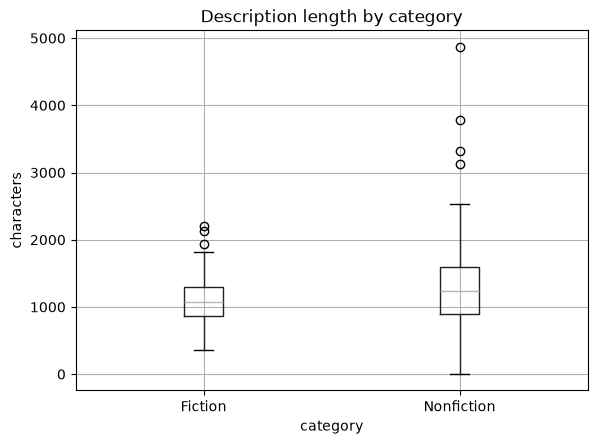

In [32]:
import matplotlib.pyplot as plt

df.boxplot(column="desc_len", by="category")
plt.title("Description length by category")
plt.suptitle("")
plt.ylabel("characters")
plt.savefig("../report/desc_length_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
import numpy as np

brightness_values = []

for path in df["image_path"]:
    img = Image.open("../" + path)
    gray = img.convert("L")
    arr = np.array(gray)
    num = arr.mean()
    brightness_values.append(num)
df["brightness"] = brightness_values
df.groupby("category")["brightness"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fiction,65.0,136.661055,54.188229,9.868679,91.589163,145.725777,181.299496,245.748830
Nonfiction,110.0,147.872296,60.860262,20.113295,99.836729,151.401968,192.578228,246.521894
